<a href="https://colab.research.google.com/github/Atharv-Vyahalkar/Yuva-Intern--Junior-Machine-Learning-Data-Analyst---Agriculture-Agribusiness/blob/main/Agriculture_Data_Preprocessing_Week2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [21]:
df = pd.read_csv("Crop Data 24-25.csv")

In [22]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 25239
Number of columns: 7


In [23]:
print("First 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

First 5 rows:


,State,District,Crop,Season,Area-2024-25,Production-2024-25,Yield-2024-25
0,Andaman And Nicobar Islands,Nicobars,Rice,Kharif,0.0,0.0,735.0
1,Andaman And Nicobar Islands,Nicobars,Rice,Total,0.0,0.0,735.0
2,Andaman And Nicobar Islands,Nicobars,Cereals,Kharif,0.0,0.0,735.0
3,Andaman And Nicobar Islands,Nicobars,Cereals,Total,0.0,0.0,735.0
4,Andaman And Nicobar Islands,Nicobars,Total Food Grains,Kharif,0.0,0.0,735.0



Last 5 rows:


,State,District,Crop,Season,Area-2024-25,Production-2024-25,Yield-2024-25
25234,West Bengal,Uttar Dinajpur,Total Pulses,Total,0.08,0.07,889.0
25235,West Bengal,Uttar Dinajpur,Total Food Grains,Kharif,2.04,5.97,2925.0
25236,West Bengal,Uttar Dinajpur,Total Food Grains,Rabi,0.84,4.90,5808.0
25237,West Bengal,Uttar Dinajpur,Total Food Grains,Summer,1.10,6.43,5845.0
25238,West Bengal,Uttar Dinajpur,Total Food Grains,Total,3.98,17.30,4341.0


In [24]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Column names:
['State', 'District', 'Crop', 'Season', 'Area-2024-25', 'Production-2024-25', 'Yield-2024-25']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25239 entries, 0 to 25238
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   State               25239 non-null  object 
 1   District            25239 non-null  object 
 2   Crop                25239 non-null  object 
 3   Season              25239 non-null  object 
 4   Area-2024-25        25239 non-null  float64
 5   Production-2024-25  25192 non-null  float64
 6   Yield-2024-25       25192 non-null  float64
dtypes: float64(3), object(4)
memory usage: 1.3+ MB


In [25]:
print("Statistical summary of numerical variables:")
display(df.describe().T)

Statistical summary of numerical variables:


,count,mean,std,min,25%,50%,75%,max
Area-2024-25,25239.0,0.342068,0.742156,0.0,0.00,0.02,0.29,8.93
Production-2024-25,25192.0,0.901558,2.118324,0.0,0.00,0.03,0.60,24.98
Yield-2024-25,25192.0,1973.578636,1411.503319,0.0,892.75,1614.00,2788.00,15033.00


In [26]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values)

Missing values in each column:


,0
State,0
District,0
Crop,0
Season,0
Area-2024-25,0
Production-2024-25,47
Yield-2024-25,47


In [27]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

display(missing_summary)

,Missing Count,Missing Percentage
State,0,0.00000
District,0,0.00000
Crop,0,0.00000
Season,0,0.00000
Area-2024-25,0,0.00000
Production-2024-25,47,0.18622
Yield-2024-25,47,0.18622


In [28]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [29]:
print("Data types of each column:")
display(df.dtypes)

Data types of each column:


,0
State,object
District,object
Crop,object
Season,object
Area-2024-25,float64
Production-2024-25,float64
Yield-2024-25,float64


**Detailed Missing-Value Investigation**

In [30]:
production_missing = df["Production-2024-25"].isnull()
yield_missing = df["Yield-2024-25"].isnull()

print("Missing Production:", production_missing.sum())
print("Missing Yield:", yield_missing.sum())

print("\nMissing in both columns:", (production_missing & yield_missing).sum())
print("Production missing but Yield available:", (production_missing & ~yield_missing).sum())
print("Yield missing but Production available:", (~production_missing & yield_missing).sum())

Missing Production: 47
Missing Yield: 47

Missing in both columns: 47
Production missing but Yield available: 0
Yield missing but Production available: 0


In [31]:
missing_records = df[production_missing & yield_missing].copy()

print("Number of affected records:", len(missing_records))

display(missing_records)

Number of affected records: 47


,State,District,Crop,Season,Area-2024-25,Production-2024-25,Yield-2024-25
1303,Arunachal Pradesh,Longding,Lentil,Rabi,0.00,NaN,NaN
1304,Arunachal Pradesh,Longding,Lentil,Total,0.00,NaN,NaN
3763,Bihar,Madhepura,Bajra,Kharif,0.00,NaN,NaN
3764,Bihar,Madhepura,Bajra,Total,0.00,NaN,NaN
4189,Bihar,Rohtas,Other Pulses,Kharif,0.00,NaN,NaN
4343,Bihar,Sheikhpura,Ragi,Kharif,0.00,NaN,NaN
4344,Bihar,Sheikhpura,Ragi,Total,0.00,NaN,NaN
4681,Chhattisgarh,Balrampur-Ramanujganj,Moong,Kharif,0.00,NaN,NaN
4682,Chhattisgarh,Balrampur-Ramanujganj,Moong,Total,0.00,NaN,NaN
4816,Chhattisgarh,Bilaspur,Moong,Kharif,0.00,NaN,NaN


In [32]:
display(
    missing_records[
        [
            "State",
            "District",
            "Crop",
            "Season",
            "Area-2024-25"
        ]
    ]
)

,State,District,Crop,Season,Area-2024-25
1303,Arunachal Pradesh,Longding,Lentil,Rabi,0.00
1304,Arunachal Pradesh,Longding,Lentil,Total,0.00
3763,Bihar,Madhepura,Bajra,Kharif,0.00
3764,Bihar,Madhepura,Bajra,Total,0.00
4189,Bihar,Rohtas,Other Pulses,Kharif,0.00
4343,Bihar,Sheikhpura,Ragi,Kharif,0.00
4344,Bihar,Sheikhpura,Ragi,Total,0.00
4681,Chhattisgarh,Balrampur-Ramanujganj,Moong,Kharif,0.00
4682,Chhattisgarh,Balrampur-Ramanujganj,Moong,Total,0.00
4816,Chhattisgarh,Bilaspur,Moong,Kharif,0.00


In [33]:
print("Area statistics for records with missing Production and Yield:")

display(
    missing_records["Area-2024-25"].describe()
)

Area statistics for records with missing Production and Yield:


,Area-2024-25
count,47.000000
mean,0.003830
std,0.012778
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,0.050000


In [34]:
print(
    "Records with Area = 0:",
    (missing_records["Area-2024-25"] == 0).sum()
)

print(
    "Records with Area > 0:",
    (missing_records["Area-2024-25"] > 0).sum()
)

Records with Area = 0: 43
Records with Area > 0: 4


In [35]:
non_zero_area_missing = missing_records[
    missing_records["Area-2024-25"] > 0
]

display(
    non_zero_area_missing[
        [
            "State",
            "District",
            "Crop",
            "Season",
            "Area-2024-25"
        ]
    ]
)

,State,District,Crop,Season,Area-2024-25
23960,Uttar Pradesh,Unnao,Jowar,Kharif,0.04
23961,Uttar Pradesh,Unnao,Jowar,Total,0.04
24003,Uttar Pradesh,Varanasi,Jowar,Kharif,0.05
24004,Uttar Pradesh,Varanasi,Jowar,Total,0.05


In [36]:
print("Missing records by season:")

display(
    missing_records["Season"].value_counts()
)

Missing records by season:


,count
Season,
Total,20
Kharif,18
Rabi,9


In [37]:
print("Missing records by crop:")

display(
    missing_records["Crop"].value_counts()
)

Missing records by crop:


,count
Crop,
Ragi,8
Moong,7
Lentil,6
Bajra,4
Jowar,4
Tur,4
Barley,2
Nutri/Coarse Cereals,2
Gram,2


In [38]:
print("Missing records by state:")

display(
    missing_records["State"].value_counts()
)

Missing records by state:


,count
State,
Chhattisgarh,14
Rajasthan,11
West Bengal,5
Bihar,5
Uttar Pradesh,4
Arunachal Pradesh,2
Himachal Pradesh,2
Jharkhand,2
Madhya Pradesh,2


In [39]:
jowar_check = df[
    (df["State"] == "Uttar Pradesh") &
    (df["District"].isin(["Unnao", "Varanasi"])) &
    (df["Crop"] == "Jowar")
]

display(
    jowar_check[
        [
            "State",
            "District",
            "Crop",
            "Season",
            "Area-2024-25",
            "Production-2024-25",
            "Yield-2024-25"
        ]
    ]
)

,State,District,Crop,Season,Area-2024-25,Production-2024-25,Yield-2024-25
23960,Uttar Pradesh,Unnao,Jowar,Kharif,0.04,NaN,NaN
23961,Uttar Pradesh,Unnao,Jowar,Total,0.04,NaN,NaN
24003,Uttar Pradesh,Varanasi,Jowar,Kharif,0.05,NaN,NaN
24004,Uttar Pradesh,Varanasi,Jowar,Total,0.05,NaN,NaN


**Missing-Value Treatment**

In [40]:
df_clean = df.copy()

print("Original dataset shape:", df_clean.shape)

df_clean = df_clean.dropna(
    subset=["Production-2024-25", "Yield-2024-25"]
)

print("Cleaned dataset shape:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))

Original dataset shape: (25239, 7)
Cleaned dataset shape: (25192, 7)
Rows removed: 47


In [41]:
print("Missing values after treatment:")
display(df_clean.isnull().sum())

Missing values after treatment:


,0
State,0
District,0
Crop,0
Season,0
Area-2024-25,0
Production-2024-25,0
Yield-2024-25,0


In [42]:
missing_comparison = pd.DataFrame({
    "Before Cleaning": df.isnull().sum(),
    "After Cleaning": df_clean.isnull().sum()
})

display(missing_comparison)

,Before Cleaning,After Cleaning
State,0,0
District,0,0
Crop,0,0
Season,0,0
Area-2024-25,0,0
Production-2024-25,47,0
Yield-2024-25,47,0


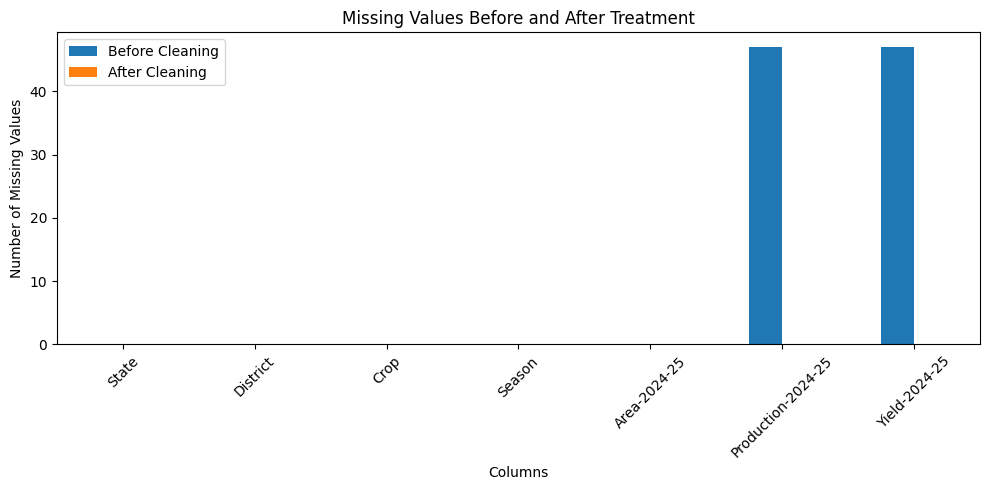

In [43]:
missing_comparison.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Missing Values Before and After Treatment")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [44]:
print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(df_clean))
print("Total rows removed:", len(df) - len(df_clean))

Rows before cleaning: 25239
Rows after cleaning: 25192
Total rows removed: 47


**Categorical & Structural Consistency Analysis**

In [45]:
categorical_columns = [
    "State",
    "District",
    "Crop",
    "Season"
]

for column in categorical_columns:
    print(f"\n{column}")
    print("-" * 40)
    print("Number of unique values:", df_clean[column].nunique())
    print("Unique values:")
    print(df_clean[column].unique())


State
----------------------------------------
Number of unique values: 31
Unique values:
['Andaman And Nicobar Islands' 'Andhra Pradesh' 'Arunachal Pradesh'
 'Assam' 'Bihar' 'Chandigarh' 'Chhattisgarh' 'Goa' 'Gujarat' 'Haryana'
 'Himachal Pradesh' 'Jammu And Kashmir' 'Jharkhand' 'Karnataka' 'Kerala'
 'Ladakh' 'Madhya Pradesh' 'Maharashtra' 'Mizoram' 'Nagaland' 'Odisha'
 'Puducherry' 'Punjab' 'Rajasthan' 'Sikkim' 'Tamil Nadu' 'Telangana'
 'Tripura' 'Uttar Pradesh' 'Uttarakhand' 'West Bengal']

District
----------------------------------------
Number of unique values: 723
Unique values:
['Nicobars' 'North And Middle Andaman' 'South Andamans'
 'Alluri Sitharama Raju' 'Anakapalli' 'Ananthapuramu' 'Annamayya'
 'Bapatla' 'Chittoor' 'Dr. B.R. Ambedkar Konaseema' 'East Godavari'
 'Eluru' 'Guntur' 'Kakinada' 'Krishna' 'Kurnool' 'Nandyal' 'Ntr' 'Palnadu'
 'Parvathipuram Manyam' 'Prakasam' 'Sri Potti Sriramulu Nellore'
 'Sri Sathya Sai' 'Srikakulam' 'Tirupati' 'Visakhapatnam' 'Vizianagaram'
 'W

In [46]:
for column in categorical_columns:
    whitespace_count = (
        df_clean[column].astype(str) != df_clean[column].astype(str).str.strip()
    ).sum()

    print(f"{column}: {whitespace_count} values with leading/trailing whitespace")

State: 0 values with leading/trailing whitespace
District: 0 values with leading/trailing whitespace
Crop: 0 values with leading/trailing whitespace
Season: 0 values with leading/trailing whitespace


In [47]:
for column in categorical_columns:
    print(f"\n{column} - case-normalized duplicates")

    normalized = df_clean[column].astype(str).str.strip().str.lower()

    comparison = pd.DataFrame({
        "Original": df_clean[column],
        "Normalized": normalized
    }).drop_duplicates()

    duplicates_after_normalization = (
        comparison.groupby("Normalized")["Original"]
        .nunique()
    )

    print(
        duplicates_after_normalization[
            duplicates_after_normalization > 1
        ]
    )


State - case-normalized duplicates
Series([], Name: Original, dtype: int64)

District - case-normalized duplicates
Series([], Name: Original, dtype: int64)

Crop - case-normalized duplicates
Series([], Name: Original, dtype: int64)

Season - case-normalized duplicates
Series([], Name: Original, dtype: int64)


In [48]:
crop_counts = (
    df_clean["Crop"]
    .value_counts()
    .sort_values(ascending=False)
)

display(crop_counts)

,count
Crop,
Total Food Grains,2597
Cereals,2525
Nutri/Coarse Cereals,2292
Maize,2026
Rice,1792
Moong,1678
Urad,1493
Shree Anna /Nutri Cereals,1459
Other Pulses,1203


In [49]:
aggregate_crops = [
    "Total Food Grains",
    "Cereals",
    "Nutri/Coarse Cereals",
    "Total Pulses"
]

aggregate_summary = pd.DataFrame({
    "Crop Category": aggregate_crops,
    "Record Count": [
        (df_clean["Crop"] == crop).sum()
        for crop in aggregate_crops
    ]
})

display(aggregate_summary)

,Crop Category,Record Count
0,Total Food Grains,2597
1,Cereals,2525
2,Nutri/Coarse Cereals,2292
3,Total Pulses,699


In [50]:
aggregate_mask = df_clean["Crop"].isin(aggregate_crops)

aggregate_count = aggregate_mask.sum()
aggregate_percentage = (aggregate_count / len(df_clean)) * 100

print("Aggregate-category records:", aggregate_count)
print(
    "Percentage of cleaned dataset:",
    round(aggregate_percentage, 2),
    "%"
)

Aggregate-category records: 8113
Percentage of cleaned dataset: 32.2 %


In [51]:
category_type = pd.Series(
    np.where(
        df_clean["Crop"].isin(aggregate_crops),
        "Aggregate",
        "Individual Crop"
    ),
    name="Category Type"
)

display(category_type.value_counts())

,count
Category Type,
Individual Crop,17079
Aggregate,8113


In [52]:
display(
    category_type.value_counts(normalize=True).mul(100).round(2)
)

,proportion
Category Type,
Individual Crop,67.8
Aggregate,32.2


In [53]:
season_counts = df_clean["Season"].value_counts()

print("Season distribution:")
display(season_counts)

Season distribution:


,count
Season,
Total,10143
Kharif,7317
Rabi,5321
Summer,2411


In [54]:
total_season_count = (
    df_clean["Season"] == "Total"
).sum()

print("Records with Season = Total:", total_season_count)

print(
    "Percentage of dataset:",
    round((total_season_count / len(df_clean)) * 100, 2),
    "%"
)

Records with Season = Total: 10143
Percentage of dataset: 40.26 %


**Outlier Detection & Analysis**

In [55]:
numerical_columns = [
    "Area-2024-25",
    "Production-2024-25",
    "Yield-2024-25"
]

display(df_clean[numerical_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
Area-2024-25,25192.0,0.342699,0.742704,0.0,0.00,0.02,0.29,8.93
Production-2024-25,25192.0,0.901558,2.118324,0.0,0.00,0.03,0.60,24.98
Yield-2024-25,25192.0,1973.578636,1411.503319,0.0,892.75,1614.00,2788.00,15033.00


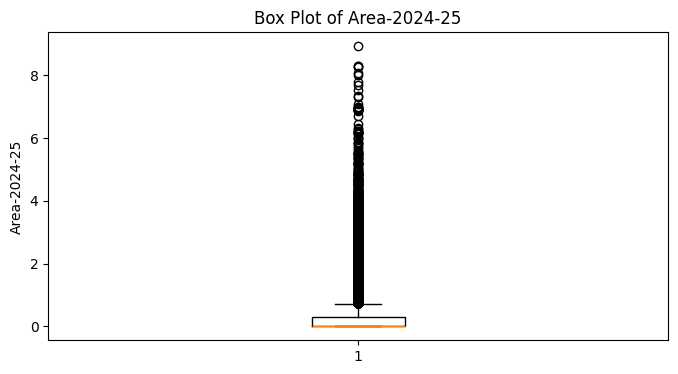

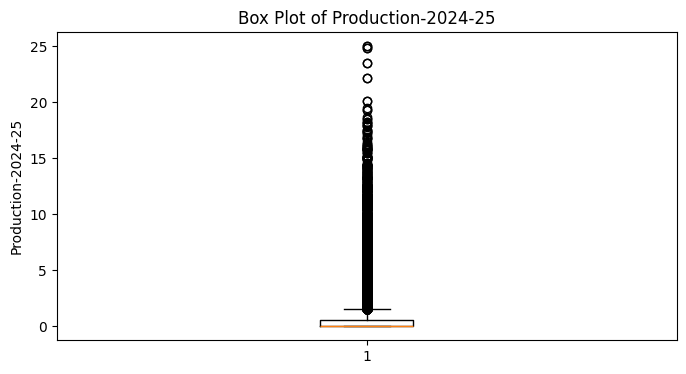

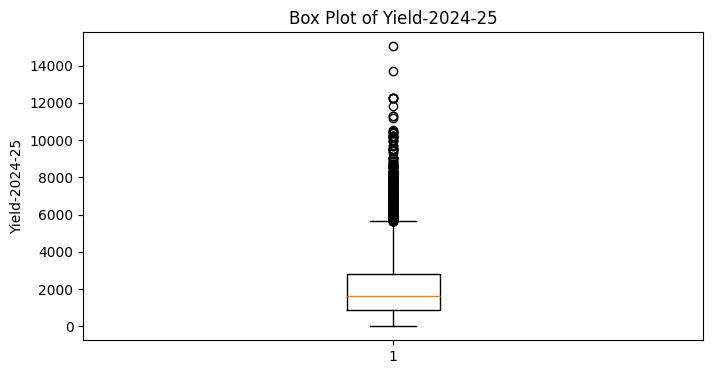

In [56]:
for column in numerical_columns:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df_clean[column])
    plt.title(f"Box Plot of {column}")
    plt.ylabel(column)
    plt.show()

In [57]:
outlier_summary = []

for column in numerical_columns:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]

    outlier_summary.append({
        "Variable": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": (len(outliers) / len(df_clean)) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary)

,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Area-2024-25,0.00,0.29,0.29,-0.435,0.725,3903,15.493014
1,Production-2024-25,0.00,0.60,0.60,-0.900,1.500,4299,17.064941
2,Yield-2024-25,892.75,2788.00,1895.25,-1950.125,5630.875,485,1.925214


In [58]:
for column in numerical_columns:
    print(f"\nTop 10 values for {column}")
    print("-" * 50)

    display(
        df_clean[
            [
                "State",
                "District",
                "Crop",
                "Season",
                column
            ]
        ]
        .sort_values(by=column, ascending=False)
        .head(10)
    )


Top 10 values for Area-2024-25
--------------------------------------------------


,State,District,Crop,Season,Area-2024-25
17035,Rajasthan,Churu,Total Food Grains,Total,8.93
13226,Maharashtra,Ahilyanagar,Total Food Grains,Total,8.30
12190,Madhya Pradesh,Narmadapuram,Total Food Grains,Total,8.29
12441,Madhya Pradesh,Raisen,Total Food Grains,Total,8.28
16787,Rajasthan,Barmer,Total Food Grains,Total,8.08
16784,Rajasthan,Barmer,Total Food Grains,Kharif,8.01
16922,Rajasthan,Bikaner,Total Food Grains,Total,7.78
9954,Karnataka,Kalaburagi,Total Food Grains,Total,7.69
14448,Maharashtra,Solapur,Total Food Grains,Total,7.52
10459,Karnataka,Vijayapura,Total Food Grains,Total,7.36



Top 10 values for Production-2024-25
--------------------------------------------------


,State,District,Crop,Season,Production-2024-25
16511,Punjab,Sangrur,Total Food Grains,Total,24.98
16501,Punjab,Sangrur,Cereals,Total,24.97
16309,Punjab,Ludhiana,Total Food Grains,Total,24.85
16297,Punjab,Ludhiana,Cereals,Total,24.80
16106,Punjab,Bathinda,Total Food Grains,Total,23.49
16096,Punjab,Bathinda,Cereals,Total,23.48
16424,Punjab,Patiala,Cereals,Total,22.15
16431,Punjab,Patiala,Total Food Grains,Total,22.15
16552,Punjab,Sri Muktsar Sahib,Total Food Grains,Total,20.14
16542,Punjab,Sri Muktsar Sahib,Cereals,Total,20.13



Top 10 values for Yield-2024-25
--------------------------------------------------


,State,District,Crop,Season,Yield-2024-25
16917,Rajasthan,Bikaner,Other Pulses,Rabi,15033.0
20079,Telangana,Nalgonda,Other Pulses,Rabi,13717.0
24644,West Bengal,Dakshin Dinajpur,Nutri/Coarse Cereals,Total,12237.0
24643,West Bengal,Dakshin Dinajpur,Nutri/Coarse Cereals,Summer,12237.0
24641,West Bengal,Dakshin Dinajpur,Maize,Summer,12237.0
24642,West Bengal,Dakshin Dinajpur,Maize,Total,12237.0
20080,Telangana,Nalgonda,Other Pulses,Total,11842.0
24863,West Bengal,Malda,Nutri/Coarse Cereals,Rabi,11295.0
24859,West Bengal,Malda,Maize,Rabi,11295.0
16998,Rajasthan,Chittorgarh,Other Pulses,Rabi,11204.0


In [59]:
skewness = df_clean[numerical_columns].skew()

print("Skewness of numerical variables:")
display(skewness)

Skewness of numerical variables:


,0
Area-2024-25,3.745388
Production-2024-25,3.870636
Yield-2024-25,1.494115


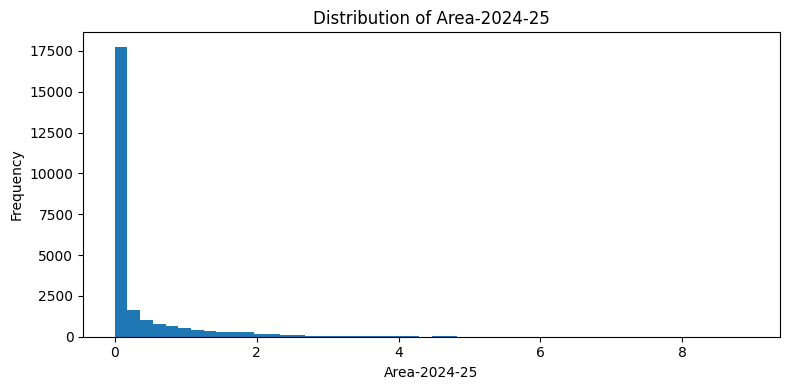

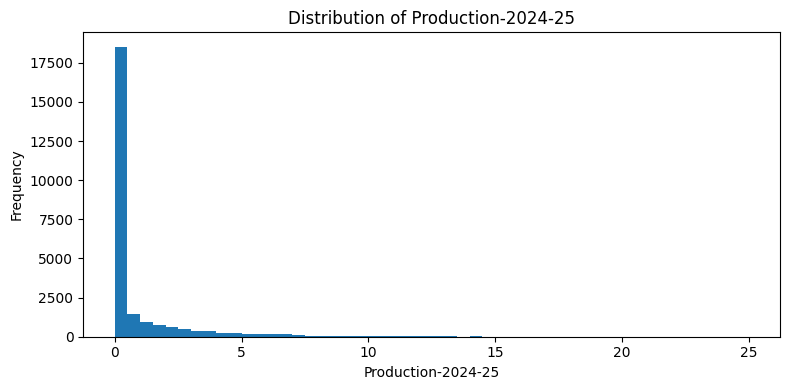

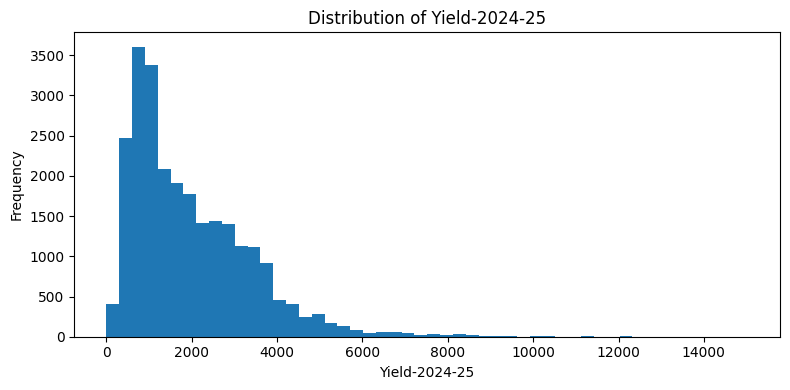

In [60]:
for column in numerical_columns:
    plt.figure(figsize=(8, 4))
    plt.hist(df_clean[column], bins=50)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

In [61]:
crop_summary = (
    df_clean
    .groupby("Crop")[numerical_columns]
    .agg(["count", "median", "mean", "std"])
)

display(crop_summary)

Area-2024-25                             \
                                 count median      mean       std   
Crop                                                                
Bajra                              875   0.00  0.167280  0.538932   
Barley                             538   0.00  0.022045  0.066651   
Cereals                           2525   0.53  0.866182  1.010140   
Gram                              1014   0.01  0.178028  0.383400   
Jowar                              963   0.00  0.082316  0.249000   
Lentil                             674   0.01  0.049436  0.116734   
Maize                             2026   0.01  0.118544  0.313665   
Moong                             1678   0.00  0.068218  0.301232   
Nutri/Coarse Cereals              2292   0.03  0.223141  0.534783   
Other Pulses                      1203   0.00  0.038761  0.197665   
Ragi                               580   0.00  0.042483  0.161187   
Rice                              1792   0.29  0.568878  0.706624   
Shree Anna /Nutri Cereals         1459   0.01  0.177183  0.492904   
Small Millets                      682   0.00  0.011056  0.030905   
Total Food Grains                 2597   0.63  1.043612  1.278478   
Total Pulses                       699   0.08  0.373920  0.800085   
Tur                               1040   0.00  0.082673  0.394489   
Urad                              1493   0.00  0.039518  0.128346   
Wheat                             1062   0.35  0.617119  0.708190   

                          Production-2024-25                             \
                                       count median      mean       std   
Crop                                                                      
Bajra                                    875  0.000  0.254903  0.735044   
Barley                                   538  0.010  0.070892  0.267380   
Cereals                                 2525  1.360  2.621814  3.348743   
Gram                                    1014  0.020  0.217357  0.456400   
Jowar                                    963  0.000  0.102253  0.280233   
Lentil                                   674  0.010  0.048220  0.121064   
Maize                                   2026  0.040  0.427117  1.137151   
Moong                                   1678  0.000  0.049583  0.250237   
Nutri/Coarse Cereals                    2292  0.075  0.555777  1.260189   
Other Pulses                            1203  0.000  0.026783  0.105993   
Ragi                                     580  0.000  0.067690  0.270308   
Rice                                    1792  0.720  1.667919  2.232252   
Shree Anna /Nutri Cereals               1459  0.010  0.253276  0.651934   
Small Millets                            682  0.000  0.011290  0.043308   
Total Food Grains                       2597  1.480  2.736018  3.452670   
Total Pulses                             699  0.060  0.347196  0.714200   
Tur                                     1040  0.000  0.068692  0.250116   
Urad                                    1493  0.000  0.028600  0.113715   
Wheat                                   1062  0.930  2.219548  2.855547   

                          Yield-2024-25                                    
                                  count  median         mean          std  
Crop                                                                       
Bajra                               875  1352.0  1569.945143   750.204655  
Barley                              538  2353.0  2431.970260   997.401977  
Cereals                            2525  2828.0  2913.796832  1104.073134  
Gram                               1014  1216.0  1219.019724   395.974253  
Jowar                               963  1222.0  1366.563863   871.237793  
Lentil                              674   902.0   884.724036   286.238138  
Maize                              2026  3177.5  3494.746298  1748.075571  
Moong                              1678   643.0   679.364124   302.325821  
Nutri/Coarse Cereals

**Aggregate vs Individual Crop Outliers**

In [62]:
aggregate_crops = [
    "Total Food Grains",
    "Cereals",
    "Nutri/Coarse Cereals",
    "Total Pulses"
]

df_clean["Crop_Type"] = np.where(
    df_clean["Crop"].isin(aggregate_crops),
    "Aggregate",
    "Individual Crop"
)

display(df_clean["Crop_Type"].value_counts())

,count
Crop_Type,
Individual Crop,17079
Aggregate,8113


In [63]:
crop_type_summary = (
    df_clean
    .groupby("Crop_Type")[numerical_columns]
    .agg(["count", "median", "mean", "std", "max"])
)

display(crop_type_summary)

Area-2024-25                                   \
                       count median      mean       std   max   
Crop_Type                                                       
Aggregate               8113   0.22  0.698901  1.047004  8.93   
Individual Crop        17079   0.01  0.173493  0.451717  6.95   

                Production-2024-25                                    \
                             count median      mean       std    max   
Crop_Type                                                              
Aggregate                     8113   0.48  1.878719  2.983339  24.98   
Individual Crop              17079   0.01  0.437380  1.312369  17.89   

                Yield-2024-25                                            
                        count  median         mean         std      max  
Crop_Type                                                                
Aggregate                8113  2460.0  2610.669419  1375.42940  12237.0  
Individual Crop         17079  1179.0  1670.942795  1325.06633  15033.0

In [64]:
outlier_by_type = []

for crop_type in df_clean["Crop_Type"].unique():

    subset = df_clean[df_clean["Crop_Type"] == crop_type]

    for column in numerical_columns:

        Q1 = subset[column].quantile(0.25)
        Q3 = subset[column].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = subset[
            (subset[column] < lower_bound) |
            (subset[column] > upper_bound)
        ]

        outlier_by_type.append({
            "Crop Type": crop_type,
            "Variable": column,
            "Records": len(subset),
            "Outlier Count": len(outliers),
            "Outlier Percentage": round(
                len(outliers) / len(subset) * 100, 2
            )
        })

outlier_by_type = pd.DataFrame(outlier_by_type)

display(outlier_by_type)

,Crop Type,Variable,Records,Outlier Count,Outlier Percentage
0,Individual Crop,Area-2024-25,17079,2938,17.20
1,Individual Crop,Production-2024-25,17079,3095,18.12
2,Individual Crop,Yield-2024-25,17079,631,3.69
3,Aggregate,Area-2024-25,8113,552,6.80
4,Aggregate,Production-2024-25,8113,666,8.21
5,Aggregate,Yield-2024-25,8113,170,2.10


In [65]:
df_clean.drop(columns=["Crop_Type"], inplace=True)

print("Temporary Crop_Type column removed.")

Temporary Crop_Type column removed.


**Preparing the Cleaned Source Dataset**

In [66]:
aggregate_crops = [
    "Total Food Grains",
    "Cereals",
    "Nutri/Coarse Cereals",
    "Total Pulses"
]

aggregate_crop_count = df_clean["Crop"].isin(aggregate_crops).sum()
total_season_count = (df_clean["Season"] == "Total").sum()

print("Aggregate crop records:", aggregate_crop_count)
print("Total-season records:", total_season_count)

Aggregate crop records: 8113
Total-season records: 10143


In [67]:
df_ml = df_clean[
    (~df_clean["Crop"].isin(aggregate_crops)) &
    (df_clean["Season"] != "Total")
].copy()

print("Cleaned dataset shape:", df_clean.shape)
print("ML-oriented dataset shape:", df_ml.shape)
print("Records excluded for ML preparation:", len(df_clean) - len(df_ml))

Cleaned dataset shape: (25192, 7)
ML-oriented dataset shape: (9795, 7)
Records excluded for ML preparation: 15397


In [68]:
print("Crop categories remaining:")
print(df_ml["Crop"].nunique())

print("\nSeason categories remaining:")
print(df_ml["Season"].unique())

print("\nRemaining aggregate crop categories:")
print(df_ml[df_ml["Crop"].isin(aggregate_crops)]["Crop"].unique())

print("\nRemaining Total-season records:")
print((df_ml["Season"] == "Total").sum())

Crop categories remaining:
15

Season categories remaining:
['Kharif' 'Rabi' 'Summer']

Remaining aggregate crop categories:
[]

Remaining Total-season records:
0


In [69]:
dataset_comparison = pd.DataFrame({
    "Dataset": [
        "Original Raw Dataset",
        "Cleaned Dataset",
        "ML-Oriented Dataset"
    ],
    "Rows": [
        len(df),
        len(df_clean),
        len(df_ml)
    ],
    "Columns": [
        df.shape[1],
        df_clean.shape[1],
        df_ml.shape[1]
    ]
})

display(dataset_comparison)

,Dataset,Rows,Columns
0,Original Raw Dataset,25239,7
1,Cleaned Dataset,25192,7
2,ML-Oriented Dataset,9795,7


**Categorical Encoding**

In [71]:
categorical_columns = [
    "State",
    "District",
    "Crop",
    "Season"
]

for column in categorical_columns:
    print(
        f"{column}: {df_ml[column].nunique()} unique categories"
    )

State: 31 unique categories
District: 723 unique categories
Crop: 15 unique categories
Season: 3 unique categories


In [72]:
print("Missing values in ML-oriented dataset:")
display(df_ml.isnull().sum())

Missing values in ML-oriented dataset:


,0
State,0
District,0
Crop,0
Season,0
Area-2024-25,0
Production-2024-25,0
Yield-2024-25,0


**Categorical Encoding**

In [73]:
from sklearn.preprocessing import OneHotEncoder

In [74]:
categorical_columns = [
    "State",
    "District",
    "Crop",
    "Season"
]

numerical_columns = [
    "Area-2024-25",
    "Production-2024-25",
    "Yield-2024-25"
]

In [75]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoded_array = encoder.fit_transform(
    df_ml[categorical_columns]
)

encoded_columns = encoder.get_feature_names_out(
    categorical_columns
)

df_encoded = pd.DataFrame(
    encoded_array,
    columns=encoded_columns,
    index=df_ml.index
)

display(df_encoded.head())

,State_Andaman And Nicobar Islands,State_Andhra Pradesh,State_Arunachal Pradesh,State_Assam,State_Bihar,State_Chandigarh,State_Chhattisgarh,State_Goa,State_Gujarat,State_Haryana,...,Crop_Ragi,Crop_Rice,Crop_Shree Anna /Nutri Cereals,Crop_Small Millets,Crop_Tur,Crop_Urad,Crop_Wheat,Season_Kharif,Season_Rabi,Season_Summer
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
6,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
8,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
15,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
17,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [76]:
print("Original ML-oriented columns:", df_ml.shape[1])
print("Encoded categorical columns:", df_encoded.shape[1])

Original ML-oriented columns: 7
Encoded categorical columns: 772


In [77]:
print("Encoded dataset shape:", df_encoded.shape)

Encoded dataset shape: (9795, 772)


In [78]:
for column in categorical_columns:
    print(f"{column}: {df_ml[column].nunique()} unique values")

print("\nTotal encoded features:", len(encoded_columns))

State: 31 unique values
District: 723 unique values
Crop: 15 unique values
Season: 3 unique values

Total encoded features: 772


In [79]:
for column in categorical_columns:
    print(f"\n{column} categories learned by encoder:")
    print(len(encoder.categories_[categorical_columns.index(column)]))


State categories learned by encoder:
31

District categories learned by encoder:
723

Crop categories learned by encoder:
15

Season categories learned by encoder:
3


**Numerical Transformation and Normalization**

In [80]:
numerical_columns = [
    "Area-2024-25",
    "Production-2024-25",
    "Yield-2024-25"
]

In [81]:
df_numeric = df_ml[numerical_columns].copy()

display(df_numeric.head())

,Area-2024-25,Production-2024-25,Yield-2024-25
0,0.00,0.00,735.0
6,0.04,0.09,2062.0
8,0.00,0.00,3177.0
15,0.00,0.00,338.0
17,0.00,0.00,355.0


In [82]:
before_stats = df_numeric.describe().T

before_stats["Skewness"] = df_numeric.skew()

display(before_stats)

,count,mean,std,min,25%,50%,75%,max,Skewness
Area-2024-25,9795.0,0.151201,0.410874,0.0,0.0,0.01,0.07,6.91,4.945005
Production-2024-25,9795.0,0.381282,1.181726,0.0,0.0,0.01,0.10,14.09,5.087101
Yield-2024-25,9795.0,1713.129045,1379.633657,0.0,760.0,1198.00,2400.00,15033.00,1.894162


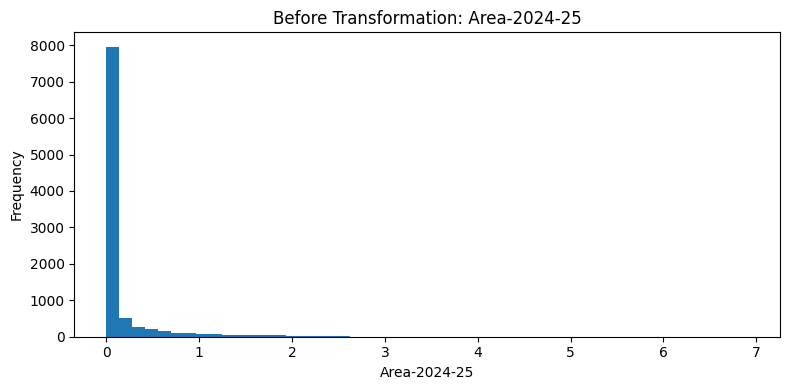

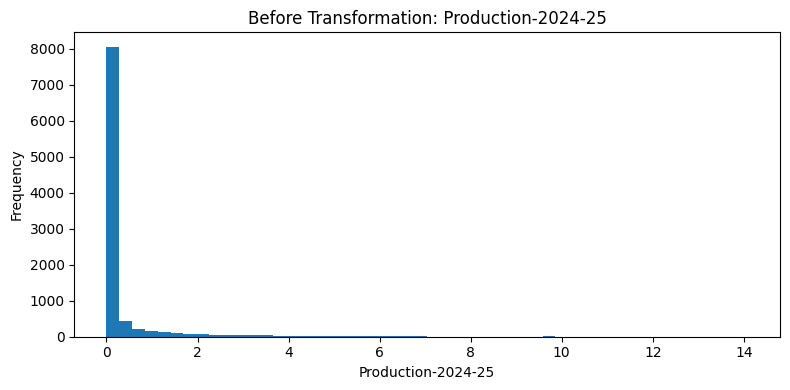

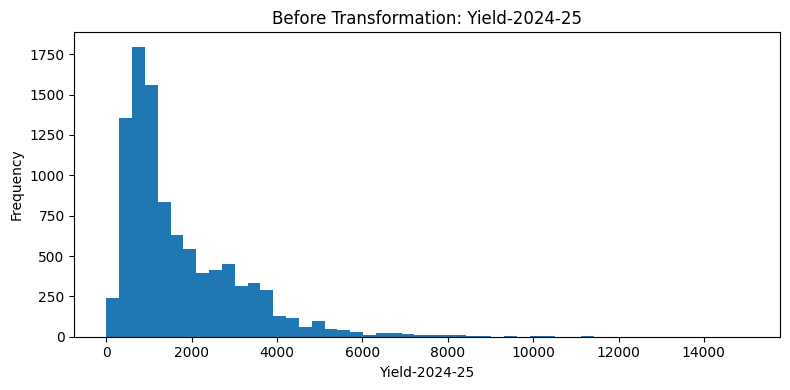

In [83]:
for column in numerical_columns:
    plt.figure(figsize=(8, 4))
    plt.hist(df_numeric[column], bins=50)
    plt.title(f"Before Transformation: {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

**Log Transformation**

In [84]:
df_log = df_numeric.copy()

for column in numerical_columns:
    df_log[column] = np.log1p(df_log[column])

display(df_log.head())

,Area-2024-25,Production-2024-25,Yield-2024-25
0,0.000000,0.000000,6.601230
6,0.039221,0.086178,7.631917
8,0.000000,0.000000,8.064007
15,0.000000,0.000000,5.826000
17,0.000000,0.000000,5.874931


In [85]:
skew_comparison = pd.DataFrame({
    "Before Transformation": df_numeric.skew(),
    "After Log Transformation": df_log.skew()
})

display(skew_comparison)

,Before Transformation,After Log Transformation
Area-2024-25,4.945005,3.074569
Production-2024-25,5.087101,2.939063
Yield-2024-25,1.894162,-0.945173


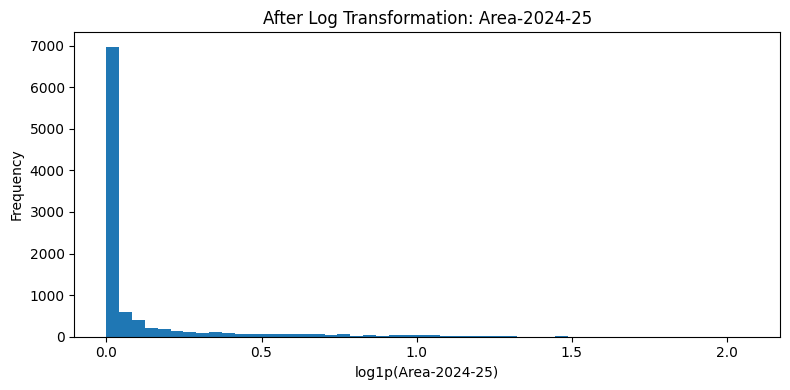

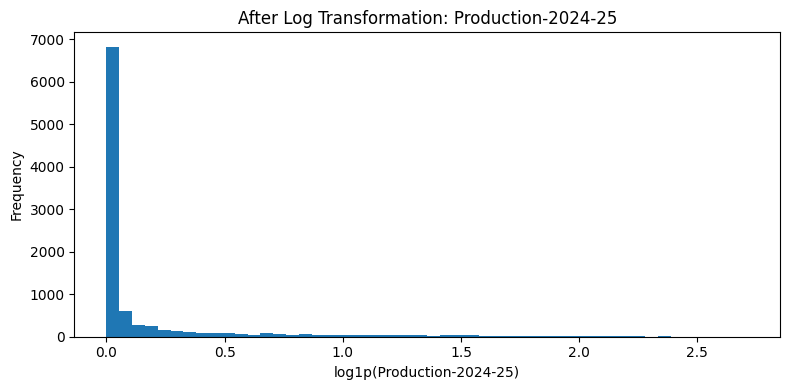

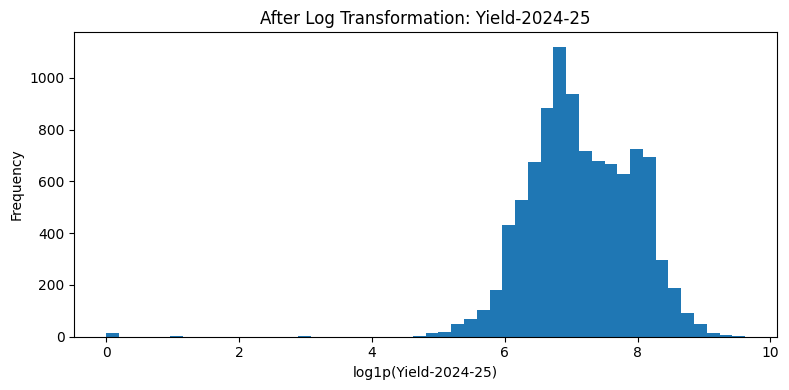

In [86]:
for column in numerical_columns:
    plt.figure(figsize=(8, 4))

    plt.hist(df_log[column], bins=50)

    plt.title(f"After Log Transformation: {column}")
    plt.xlabel(f"log1p({column})")
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

**Normalization / Scaling**

In [87]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_array = scaler.fit_transform(df_log)

df_scaled = pd.DataFrame(
    scaled_array,
    columns=numerical_columns,
    index=df_log.index
)

display(df_scaled.head())

,Area-2024-25,Production-2024-25,Yield-2024-25
0,-0.446809,-0.440535,-0.684050
6,-0.279942,-0.235604,0.591325
8,-0.446809,-0.440535,1.125996
15,-0.446809,-0.440535,-1.643323
17,-0.446809,-0.440535,-1.582776


In [88]:
scaling_check = pd.DataFrame({
    "Mean": df_scaled.mean(),
    "Standard Deviation": df_scaled.std()
})

display(scaling_check)

,Mean,Standard Deviation
Area-2024-25,9.285296e-17,1.000051
Production-2024-25,3.772151e-17,1.000051
Yield-2024-25,9.633494e-16,1.000051


In [89]:
final_numeric_summary = df_scaled.describe().T

final_numeric_summary["Skewness"] = df_scaled.skew()

display(final_numeric_summary)

,count,mean,std,min,25%,50%,75%,max,Skewness
Area-2024-25,9795.0,9.285296e-17,1.000051,-0.446809,-0.446809,-0.404474,-0.158951,8.352171,3.074569
Production-2024-25,9795.0,3.772151e-17,1.000051,-0.440535,-0.440535,-0.416873,-0.213886,6.013473,2.939063
Yield-2024-25,9795.0,9.633494e-16,1.000051,-8.852437,-0.642717,-0.080181,0.779069,3.048998,-0.945173


**Construct the Final ML-Ready Dataset**

In [90]:
df_ml_ready = pd.concat(
    [
        df_encoded,
        df_scaled
    ],
    axis=1
)

print("Final ML-ready dataset shape:", df_ml_ready.shape)

display(df_ml_ready.head())

Final ML-ready dataset shape: (9795, 775)


,State_Andaman And Nicobar Islands,State_Andhra Pradesh,State_Arunachal Pradesh,State_Assam,State_Bihar,State_Chandigarh,State_Chhattisgarh,State_Goa,State_Gujarat,State_Haryana,...,Crop_Small Millets,Crop_Tur,Crop_Urad,Crop_Wheat,Season_Kharif,Season_Rabi,Season_Summer,Area-2024-25,Production-2024-25,Yield-2024-25
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,-0.446809,-0.440535,-0.684050
6,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,-0.279942,-0.235604,0.591325
8,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.446809,-0.440535,1.125996
15,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,-0.446809,-0.440535,-1.643323
17,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.446809,-0.440535,-1.582776


In [91]:
print("Total missing values in ML-ready dataset:")

print(df_ml_ready.isnull().sum().sum())

Total missing values in ML-ready dataset:
0


In [92]:
print("Infinite values:", np.isinf(df_ml_ready).sum().sum())

Infinite values: 0


In [93]:
final_scaling_check = df_ml_ready[numerical_columns].agg(
    ["mean", "std", "min", "max"]
).T

display(final_scaling_check)

,mean,std,min,max
Area-2024-25,9.285296e-17,1.000051,-0.446809,8.352171
Production-2024-25,3.772151e-17,1.000051,-0.440535,6.013473
Yield-2024-25,9.633494e-16,1.000051,-8.852437,3.048998


In [94]:
preprocessing_summary = pd.DataFrame({
    "Stage": [
        "Original Dataset",
        "After Missing-Value Treatment",
        "ML-Oriented Dataset",
        "Final ML-Ready Dataset"
    ],
    "Rows": [
        len(df),
        len(df_clean),
        len(df_ml),
        len(df_ml_ready)
    ],
    "Columns": [
        df.shape[1],
        df_clean.shape[1],
        df_ml.shape[1],
        df_ml_ready.shape[1]
    ]
})

display(preprocessing_summary)

,Stage,Rows,Columns
0,Original Dataset,25239,7
1,After Missing-Value Treatment,25192,7
2,ML-Oriented Dataset,9795,7
3,Final ML-Ready Dataset,9795,775


In [95]:
print("FINAL DATA QUALITY CHECK")
print("=" * 40)

print("Rows:", df_ml_ready.shape[0])
print("Columns:", df_ml_ready.shape[1])
print("Missing values:", df_ml_ready.isnull().sum().sum())
print("Infinite values:", np.isinf(df_ml_ready).sum().sum())
print("Duplicate rows:", df_ml_ready.duplicated().sum())

FINAL DATA QUALITY CHECK
Rows: 9795
Columns: 775
Missing values: 0
Infinite values: 0
Duplicate rows: 0


**Before/After Preprocessing Evidence**

In [96]:
missing_summary = pd.DataFrame({
    "Stage": [
        "Original Dataset",
        "After Missing-Value Treatment"
    ],
    "Rows": [
        len(df),
        len(df_clean)
    ],
    "Missing Records Removed": [
        0,
        len(df) - len(df_clean)
    ]
})

display(missing_summary)

,Stage,Rows,Missing Records Removed
0,Original Dataset,25239,0
1,After Missing-Value Treatment,25192,47


In [97]:
skewness_summary = pd.DataFrame({
    "Variable": numerical_columns,
    "Before Transformation": df_numeric[numerical_columns].skew().values,
    "After Log Transformation": df_log[numerical_columns].skew().values
})

skewness_summary["Absolute Skewness Reduction"] = (
    skewness_summary["Before Transformation"].abs()
    - skewness_summary["After Log Transformation"].abs()
)

display(skewness_summary.round(4))

,Variable,Before Transformation,After Log Transformation,Absolute Skewness Reduction
0,Area-2024-25,4.9450,3.0746,1.8704
1,Production-2024-25,5.0871,2.9391,2.1480
2,Yield-2024-25,1.8942,-0.9452,0.9490


/tmp/ipykernel_3059/3160103345.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


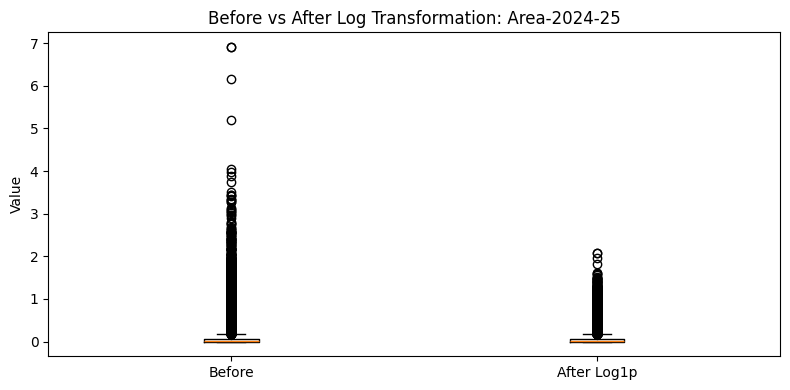

/tmp/ipykernel_3059/3160103345.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


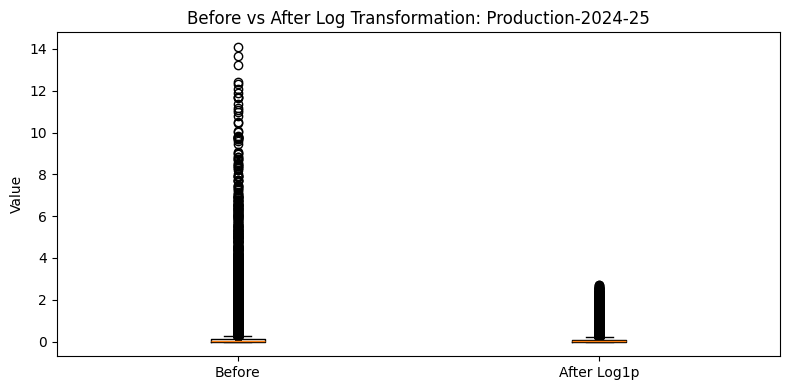

/tmp/ipykernel_3059/3160103345.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


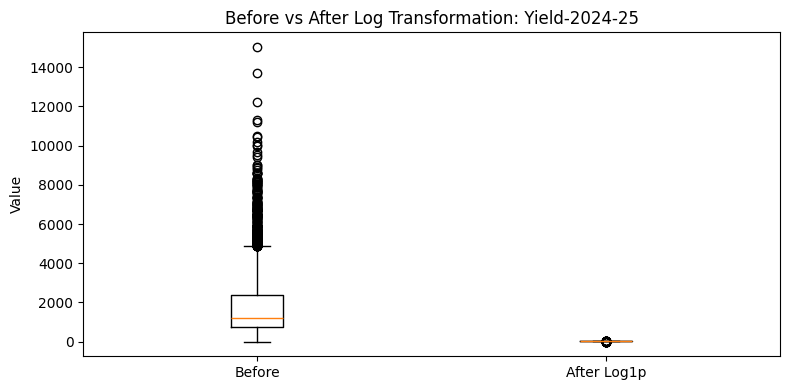

In [98]:
for column in numerical_columns:
    plt.figure(figsize=(8, 4))

    plt.boxplot(
        [df_numeric[column], df_log[column]],
        labels=["Before", "After Log1p"]
    )

    plt.title(f"Before vs After Log Transformation: {column}")
    plt.ylabel("Value")
    plt.tight_layout()
    plt.show()

In [99]:
final_statistics = pd.DataFrame({
    "Mean": df_scaled.mean(),
    "Std Dev": df_scaled.std(),
    "Minimum": df_scaled.min(),
    "Maximum": df_scaled.max()
})

display(final_statistics.round(4))

,Mean,Std Dev,Minimum,Maximum
Area-2024-25,0.0,1.0001,-0.4468,8.3522
Production-2024-25,0.0,1.0001,-0.4405,6.0135
Yield-2024-25,0.0,1.0001,-8.8524,3.0490


In [100]:
final_summary = pd.DataFrame({
    "Stage": [
        "Original Dataset",
        "Cleaned Source Dataset",
        "ML-Oriented Dataset",
        "One-Hot Encoded Features",
        "Final ML-Ready Dataset"
    ],
    "Rows": [
        len(df),
        len(df_clean),
        len(df_ml),
        len(df_ml),
        len(df_ml_ready)
    ],
    "Columns": [
        df.shape[1],
        df_clean.shape[1],
        df_ml.shape[1],
        df_encoded.shape[1],
        df_ml_ready.shape[1]
    ]
})

display(final_summary)

,Stage,Rows,Columns
0,Original Dataset,25239,7
1,Cleaned Source Dataset,25192,7
2,ML-Oriented Dataset,9795,7
3,One-Hot Encoded Features,9795,772
4,Final ML-Ready Dataset,9795,775


In [101]:
df_ml_ready.to_csv(
    "Agricultural_ML_Ready_Week2.csv",
    index=False
)

print("Final ML-ready dataset saved successfully.")

Final ML-ready dataset saved successfully.


In [102]:
import os

print(
    "File exists:",
    os.path.exists("Agricultural_ML_Ready_Week2.csv")
)

print(
    "File size (MB):",
    round(
        os.path.getsize("Agricultural_ML_Ready_Week2.csv") / (1024 * 1024),
        2
    )
)

File exists: True
File size (MB): 29.42
